[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/05_scaling_pretraining.ipynb)

# 05 · Making Pretraining Scale: Tokenisers, the Optimiser Recipe, and Size Against Data

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| **05** | **Making it scale** | **Tokenisers, the optimiser recipe, scaling laws** | **A recipe that keeps improving with size** | **Discrete tokens only** |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

Notebooks 01 to 04 fixed three things without discussion: the vocabulary (81 whole words), the training recipe
(AdamW, one learning rate, 1,500 steps) and the size of the model. Real pretraining depends on all three, and most of
the engineering of large language models is in them. This notebook opens each one.

* **Part A, tokenisers.** Real text has no fixed list of words. We spell our synthetic language out in characters and
  learn a sub-word vocabulary with byte-pair encoding ([Sennrich et al., 2015](https://arxiv.org/abs/1508.07909)), the method behind GPT's tokeniser.
* **Part B, the recipe.** Learning rate, warm-up and schedule ([Loshchilov & Hutter, 2016](https://arxiv.org/abs/1608.03983)), gradient clipping, weight decay
  done two ways (Adam, [Kingma & Ba, 2014](https://arxiv.org/abs/1412.6980); AdamW, [Loshchilov & Hutter, 2017](https://arxiv.org/abs/1711.05101)), weight tying ([Press & Wolf, 2016](https://arxiv.org/abs/1608.05859)) and context length.
* **Part C, scale.** How quality depends on model size, on data and on the compute budget ([Kaplan et al., 2020](https://arxiv.org/abs/2001.08361),
  [Hoffmann et al., 2022](https://arxiv.org/abs/2203.15556)), and when the ability to use context appears.

## Learning objectives

1. Implement byte-pair encoding, and explain what a sub-word vocabulary buys and what it costs.
2. Explain each ingredient of the standard training recipe and measure what it does.
3. Read a model-size against data-size table: when a larger model helps, when it hurts, and what a compute budget
   changes.
4. Recognise an ability appearing during training, and how its timing depends on model size.

**Runtime:** about 22 minutes on a laptop CPU (about 45 short training runs).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from prelib import world as W, transformer as T, scale as S, viz, metrics, set_seed, CKPT_DIR
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
train, test = W.corpus("train"), W.corpus("test")
BASE = dict(pos="relative", norm="pre", norm_type="rms", ffn="swiglu")    # the causal model of notebook 04: 2 layers, pre-norm, relative position bias
counts = S.word_counts(train["tokens"])                                    # how often each of the 78 words occurs in the training documents
print(f"{len(counts)} distinct words; the five most frequent:", sorted(counts.items(), key=lambda kv: -kv[1])[:5])

78 distinct words; the five most frequent: [('ask', 75620), ('set', 54480), ('dasek', 42622), ('vabom', 38871), ('gosis', 35147)]


# Part A · Tokenisers

## 1. From characters to words: byte-pair encoding

A model reads integers, so text must first be cut into pieces from a fixed list. There are two obvious lists and
both have a problem.

* **Whole words.** Short sequences, but the list is never complete: a new word, a name or a typo has no entry.
* **Characters.** The list is tiny and complete, but sequences are several times longer, and the model has to learn
  spelling before it can learn anything else.

**Byte-pair encoding** (BPE; [Sennrich et al., 2015](https://arxiv.org/abs/1508.07909)) builds a list in between, from the data:

1. start with every word spelled as characters, plus a marker `_` for the end of a word;
2. count every adjacent pair of symbols in the corpus;
3. merge the most frequent pair into one new symbol, everywhere;
4. repeat for as many merges as the vocabulary should have.

Frequent words end up as single symbols, rare words as a few pieces, and any string can still be spelled. The words
of our synthetic language were built from a three-letter stem and one of six endings (`-a`, `-ek`, `-is`, `-om`,
`-ur`, `-ly`) that marks the word's class. Watch what BPE finds first.

178 merges turn every word into a single symbol. The first 12, in order:
   1.  'k' + '_'  ->  'k_'      (the pair occurred 223,094 times)
   2.  'u' + 'r'  ->  'ur'      (the pair occurred 186,179 times)
   3.  'i' + 's'  ->  'is'      (the pair occurred 155,665 times)
   4.  'is' + '_'  ->  'is_'      (the pair occurred 149,098 times)
   5.  'e' + 'k_'  ->  'ek_'      (the pair occurred 147,474 times)
   6.  'ur' + '_'  ->  'ur_'      (the pair occurred 147,265 times)
   7.  'y' + '_'  ->  'y_'      (the pair occurred 145,747 times)
   8.  'l' + 'y_'  ->  'ly_'      (the pair occurred 145,747 times)
   9.  'o' + 'm'  ->  'om'      (the pair occurred 145,434 times)
  10.  'om' + '_'  ->  'om_'      (the pair occurred 145,434 times)
  11.  'a' + '_'  ->  'a_'      (the pair occurred 140,260 times)
  12.  'a' + 's'  ->  'as'      (the pair occurred 126,815 times)


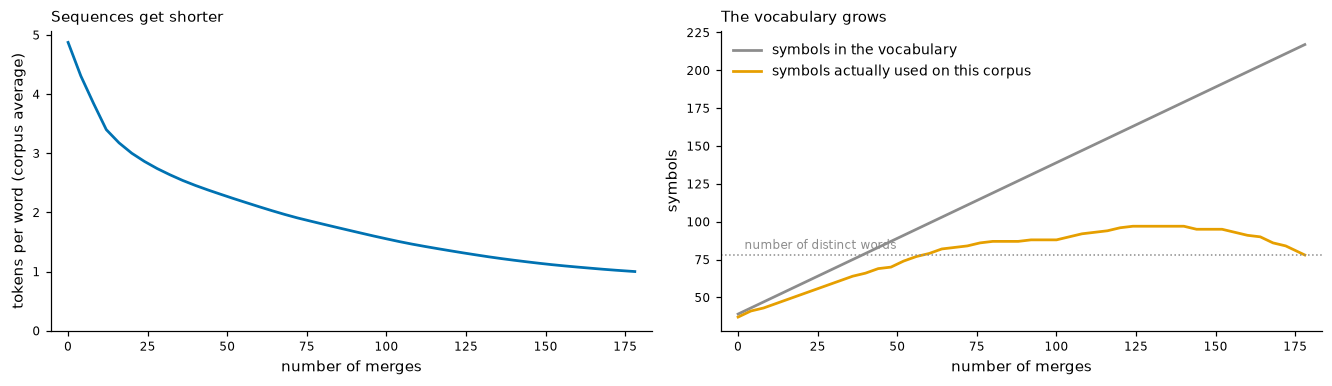

,0 merges,6 merges,12 merges,40 merges,100 merges,178 merges
nekly,n e k l y _,n e k l y _,n e k ly_,ne k ly_,nekly_,nekly_
zamis,z a m i s _,z a m is_,z a m is_,za m is_,zamis_,zamis_
dasek,d a s e k _,d a s ek_,d as ek_,dasek_,dasek_,dasek_
set,s e t _,s e t _,s e t _,set_,set_,set_
D,D _,D _,D _,D _,D_,D_
5,5 _,5 _,5 _,5 _,5_,5_


In [2]:
merges = S.train_bpe(counts, 200)                 # asks for 200; it stops earlier, when every word is one symbol
ALL = len(merges)
print(f"{ALL} merges turn every word into a single symbol. The first 12, in order:")
for k, (a, b, n) in enumerate(merges[:12], 1):
    print(f"  {k:2d}.  '{a}' + '{b}'  ->  '{a + b}'      (the pair occurred {n:,} times)")

steps_k = sorted(set(range(0, ALL + 1, 4)) | {ALL})
toks = {k: S.Tokenizer(counts, k) for k in steps_k}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(steps_k, [toks[k].tokens_per_word(counts) for k in steps_k], color=viz.BLUE)
axes[0].set_xlabel("number of merges"); axes[0].set_ylabel("tokens per word (corpus average)"); axes[0].set_ylim(0); axes[0].set_title("Sequences get shorter")
axes[1].plot(steps_k, [toks[k].vocab for k in steps_k], color=viz.GREY, label="symbols in the vocabulary")
axes[1].plot(steps_k, [len(toks[k].used(counts)) for k in steps_k], color=viz.ORANGE, label="symbols actually used on this corpus")
axes[1].axhline(len(counts), color=viz.GREY, ls=":", lw=1); axes[1].text(2, len(counts) + 4, "number of distinct words", fontsize=8, color=viz.GREY)
axes[1].set_xlabel("number of merges"); axes[1].set_ylabel("symbols"); axes[1].set_title("The vocabulary grows"); axes[1].legend()
plt.show()
examples = ["nekly", "zamis", "dasek", "set", "D", "5"]
display(pd.DataFrame({f"{k} merges": [" ".join(S.Tokenizer(counts, k).split(w)) for w in examples] for k in (0, 6, 12, 40, 100, ALL)}, index=examples))

In [3]:
sentence = [W.WORDS[t] for t in test["tokens"][3][1:10]]
fig, ax = plt.subplots(figsize=(13, 2.6))
def frame(k):
    ax.clear()
    tok = S.Tokenizer(counts, k)
    pieces = [p for w in sentence for p in tok.split(w)]
    newest = (merges[k - 1][0] + merges[k - 1][1]) if k else None
    colors = [viz.ORANGE if p == newest else viz.SKY if len(p.rstrip("_")) > 1 or (p.endswith("_") and len(p) > 1) else "#F2F2F2" for p in pieces]
    viz.token_strip(ax, pieces, colors=colors, wrap=22, fontsize=7)
    what = f"newest symbol '{newest}'" if k else "characters only"
    ax.set_title(f"{k:3d} merges ({what}): '{' '.join(sentence)}' is {len(pieces)} tokens", fontsize=9, loc="left")
viz.save_gif(fig, frame, list(range(0, 61, 2)) + [80, 100, 120, 140, 160, ALL], "nb05_bpe_merges.gif", fps=4)

saved figures/nb05_bpe_merges.gif  (37 frames drawn, 224 kB)


'figures/nb05_bpe_merges.gif'

![Byte-pair encoding on one sentence: the word endings are merged first, then frequent whole words, until every word is a single token](figures/nb05_bpe_merges.gif)

### Try it: choose the number of merges

Static preview at the default settings {'merges_done': 12, 'document': 3}. Run the notebook to get the controls.


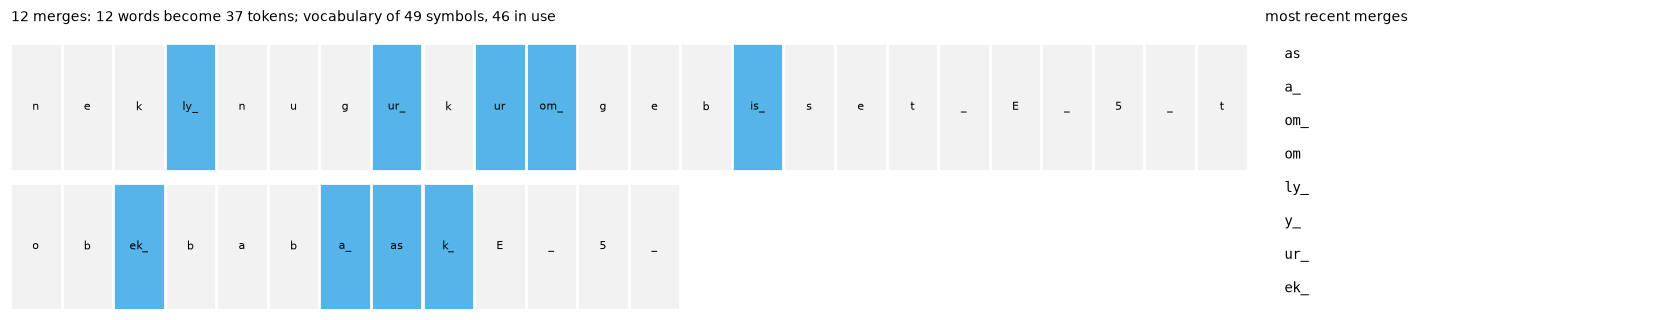

In [4]:
def bpe_explorer(merges_done=12, document=3):
    tok = S.Tokenizer(counts, merges_done)
    words = [W.WORDS[t] for t in test["tokens"][document][1:13]]
    pieces = [p for w in words for p in tok.split(w)]
    fig, axes = plt.subplots(1, 2, figsize=(15, 2.8), gridspec_kw=dict(width_ratios=[3.2, 1]))
    viz.token_strip(axes[0], pieces, colors=[viz.SKY if len(p) > 1 and p != "_" else "#F2F2F2" for p in pieces], wrap=24, fontsize=7)
    axes[0].set_title(f"{len(tok.merges)} merges: 12 words become {len(pieces)} tokens; vocabulary of {tok.vocab - 2} symbols, {len(tok.used(counts))} in use", fontsize=9, loc="left")
    recent = [a + b for a, b, _ in tok.merges[-8:]][::-1]
    axes[1].axis("off"); axes[1].set_title("most recent merges", fontsize=9)
    for i, r in enumerate(recent):
        axes[1].text(0.05, 0.9 - i * 0.12, r, fontsize=9, family="monospace")
    plt.show()
viz.explore(bpe_explorer, merges_done=(0, ALL, 2, 12), document=(0, 50, 1, 3))

**What BPE found.** Nobody told the algorithm that these words have stems and endings. The six endings are simply
the most frequent character sequences in the corpus, so they are merged first: all six (`ek_`, `is_`, `ur_`, `ly_`,
`om_`, `a_`) exist after 11 merges, and the average word falls from 4.87 tokens to 3.40 after 12. Then come the
frequent whole words, and after 178 merges every word is a single symbol.

The right-hand panel above shows a cost that is easy to miss. The vocabulary keeps every symbol ever created, about
215 by the end, but only 78 of them are still used when the corpus is tokenised. The rest are intermediate pieces,
such as `ig` or `as`, that were absorbed into longer symbols. They still have rows in the model's tables. Section 3
shows what happens when one of them is finally needed.

## 2. Does the tokeniser change what the model learns?

We train the same transformer on the same documents under five tokenisers, from characters to whole words. To keep
the character-level sequences affordable, the documents here are the first 16 words of each training document.

Loss per token cannot be compared across tokenisers: a model that predicts one character at a time has an easier job
at each step and more steps to do. The comparable quantity is the **loss per word**: the total loss over all of a
document's tokens, divided by its number of words. We report its gap to the oracle's loss per word, as before.

characters                 4.87 tokens per word   gap per word 0.267   (51s)
12 merges (the endings)    3.40 tokens per word   gap per word 0.181   (33s)
40 merges                  2.46 tokens per word   gap per word 0.132   (32s)
100 merges                 1.55 tokens per word   gap per word 0.090   (26s)
178 merges (whole words)   1.00 tokens per word   gap per word 0.061   (13s)


,symbols in use,tokens per word,longest document (tokens),gap to floor per word,seconds
characters,37.0,4.874,97.0,0.267,51.0
12 merges (the endings),46.0,3.399,65.0,0.181,33.0
40 merges,66.0,2.455,62.0,0.132,32.0
100 merges,88.0,1.553,48.0,0.090,26.0
178 merges (whole words),78.0,1.000,17.0,0.061,13.0


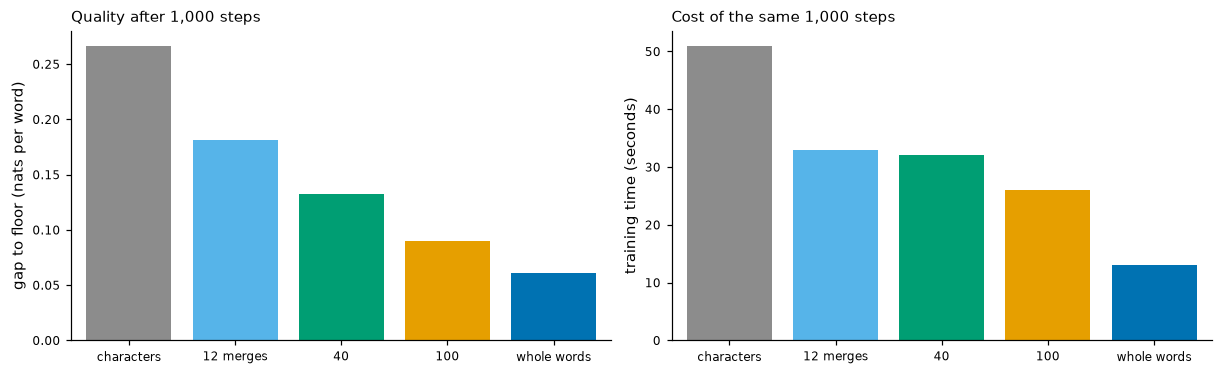

In [5]:
N_WORDS = 16
def train_tokenised(n_merges, steps=1000):
    tok = S.Tokenizer(counts, n_merges)
    xtr, _ = tok.encode(train["tokens"], N_WORDS); xte, nte = tok.encode(test["tokens"], N_WORDS)
    set_seed(0); m = T.Transformer(vocab=tok.vocab, **BASE); t0 = time.time()
    S.fit(m, xtr, steps=steps, pad=0)
    return dict(tok=tok, model=m, seconds=time.time() - t0, gap=S.per_word_loss(m, xte, nte, N_WORDS) - S.floor_per_word("test", N_WORDS),
                longest=xtr.shape[1], per_word=tok.tokens_per_word(counts))
TOK = {"characters": 0, "12 merges (the endings)": 12, "40 merges": 40, "100 merges": 100, f"{ALL} merges (whole words)": ALL}
tk = {}
for name, k in TOK.items():
    tk[name] = train_tokenised(k)
    print(f"{name:26s} {tk[name]['per_word']:.2f} tokens per word   gap per word {tk[name]['gap']:.3f}   ({tk[name]['seconds']:.0f}s)")
tok_table = pd.DataFrame({name: {"symbols in use": len(r["tok"].used(counts)), "tokens per word": r["per_word"], "longest document (tokens)": r["longest"],
                                 "gap to floor per word": r["gap"], "seconds": round(r["seconds"])} for name, r in tk.items()}).T
display(tok_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
cols = [viz.GREY, viz.SKY, viz.GREEN, viz.ORANGE, viz.BLUE]
axes[0].bar(range(5), tok_table["gap to floor per word"], color=cols); axes[0].set_ylabel("gap to floor (nats per word)"); axes[0].set_title("Quality after 1,000 steps")
axes[1].bar(range(5), tok_table["seconds"], color=cols); axes[1].set_ylabel("training time (seconds)"); axes[1].set_title("Cost of the same 1,000 steps")
for ax in axes:
    ax.set_xticks(range(5)); ax.set_xticklabels(["characters", "12 merges", "40", "100", "whole words"])
plt.show()

**Reading the result.** With the same model and the same 1,000 steps, larger pieces are better on both counts. The
gap per word falls from 0.267 with characters to 0.181, 0.132, 0.090 and 0.061 with whole words, and the training
time falls from about 70 seconds to about 15. A character model has to predict five symbols to get one word right, it has to
learn the spelling of every word before it can use it, and its sequences are up to 97 tokens long where the
whole-word model's are 17.

This does not show that a character model could not reach the same quality with more training; we did not run that.
It shows why nobody trains on characters by choice: for text made of words the model has seen, every merge buys
shorter sequences and a head start.

## 3. A word the model has never seen

The case for sub-words is the word that is not in the list. We make some: take the three-letter stem of one word and
the ending of another class, giving strings such as `digis` or `nekom` that never occur in training. In each of 1,000
test documents we replace one ordinary word by a new word **with the same ending**, so the document is still
grammatical, and measure the loss on the word that follows. The ending carries the word's class, and the class is
what predicts the next word. A model that can read the ending of a word it has never seen should be almost
undisturbed.

995 documents; some of the new words: ['musek', 'toba', 'lisly', 'nizom', 'tonis', 'nekek', 'sora', 'lizom']


,"loss on the next word, original document",after a never-seen word,increase,how the new word 'digis' is cut
characters,3.2446,3.342373,0.097774,d i g i s _
12 merges (the endings),3.182084,3.234378,0.052294,d i g is_
40 merges,3.074576,3.281861,0.207285,d i g is_
100 merges,3.02158,3.192872,0.171292,d ig is_
178 merges (whole words),2.986449,4.82109,1.834641,d ig is_


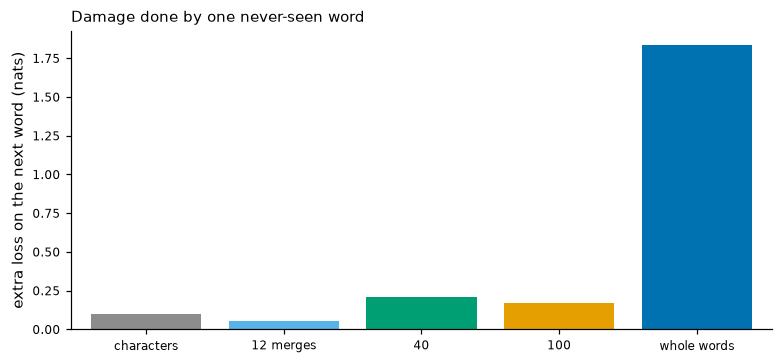

In [6]:
rng = np.random.default_rng(0)
known, fillers = set(W.WORDS), W.WORDS[W.FILL0:]
plain, novel, after, made = [], [], [], []
for d in test["tokens"][:1000]:
    words = [W.WORDS[t] for t in d[1:1 + N_WORDS]]
    cand = [i for i in range(2, N_WORDS - 1) if W.WORD_CLASS[d[1 + i]] >= 0 and W.WORD_CLASS[d[2 + i]] >= 0]
    if not cand:
        continue
    i = int(rng.choice(cand)); ending = W.SUFFIX[W.WORD_CLASS[d[1 + i]]]
    new = words[i]
    while new in known:
        new = fillers[rng.integers(len(fillers))][:3] + ending                    # a stem from anywhere, the same ending
    plain.append(words); novel.append(words[:i] + [new] + words[i + 1:]); after.append(i + 1); made.append(new)
print(f"{len(plain)} documents; some of the new words: {made[:8]}")
oov = {}
for name, r in tk.items():
    a = S.word_losses(r["model"], *r["tok"].encode_lists(plain), after).mean()
    b = S.word_losses(r["model"], *r["tok"].encode_lists(novel), after).mean()
    oov[name] = {"loss on the next word, original document": a, "after a never-seen word": b, "increase": b - a,
                 "how the new word 'digis' is cut": " ".join(r["tok"].split("digis"))}
oov = pd.DataFrame(oov).T
display(oov.round(3))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(5), oov["increase"].astype(float), color=cols); ax.set_xticks(range(5)); ax.set_xticklabels(["characters", "12 merges", "40", "100", "whole words"])
ax.set_ylabel("extra loss on the next word (nats)"); ax.set_title("Damage done by one never-seen word")
plt.show()

**Reading the result.** This is the other side of the trade.

* The **whole-word** model is badly thrown by a single new word: the loss on the *next* word rises by 1.83 nats,
  from 2.99 to 4.82. Its tokeniser can still spell `digis`, as `d ig is_`, but during training every word was one
  symbol, so the model has never once seen those pieces. They are in the vocabulary and mean nothing to it.
* The **character** model and the model with **12 merges** barely notice (increases of 0.10 and 0.05). They read
  the ending, which is all that matters for predicting the next word, and they have read endings from pieces in
  every training document.
* The two vocabularies in between are in between (0.21 and 0.17): their frequent words are single symbols, so they
  have had less practice at reading an ending from pieces.

Sections 2 and 3 together are the argument for sub-word vocabularies. Large pieces are efficient and brittle; small
pieces are robust and slow. Real vocabularies, of 30,000 to 50,000 pieces, keep common words whole and spell rare
ones out, and BPE finds that compromise from the data.

# Part B · The training recipe

From here on we return to whole-word tokens and full 64-token documents. Every notebook so far trained with the same
settings: AdamW, a constant learning rate of 0.002, gradient clipping at 1.0. This part changes them one at a time.

## 4. Learning rate, warm-up and schedule

The **learning rate** sets the size of each update. Too small and training crawls; too large and the first updates,
made from a random starting point, throw the model somewhere it does not recover from. **Warm-up** raises the rate
from zero over the first few hundred steps, so that the large rate arrives only once the gradients have become
reliable. After the warm-up the rate is usually decayed; the common choice today is half a cosine wave
([Loshchilov & Hutter, 2016](https://arxiv.org/abs/1608.03983)):
$$\eta_t = \eta_\text{peak}\cdot\begin{cases} t / T_\text{warm} & t < T_\text{warm} \\[2pt]
\tfrac12\big(1 + \cos\big(\pi\,\tfrac{t - T_\text{warm}}{T - T_\text{warm}}\big)\big) & t \ge T_\text{warm}. \end{cases}$$

The cell trains the same model for 600 steps at four peak learning rates, each with and without 200 warm-up steps,
all with cosine decay, and once more with a constant rate for comparison.

In [7]:
def recipe_run(lr, warmup=0, schedule="cosine", steps=600, **kw):
    set_seed(0); m = T.Transformer(**BASE)
    r = S.fit(m, train["tokens"], steps=steps, lr=lr, warmup=warmup, schedule=schedule, **kw)
    r["gap"] = W.evaluate_lm(m.logprobs)["gap"]
    return r
LRS, WARM = [5e-4, 2e-3, 8e-3, 3e-2], [0, 200]
grid = {(lr, wu): recipe_run(lr, wu) for lr in LRS for wu in WARM}
constant = recipe_run(8e-3, 200, schedule="constant")
gap_grid = pd.DataFrame([[grid[(lr, wu)]["gap"] for lr in LRS] for wu in WARM], index=["no warm-up", "200 warm-up steps"], columns=[f"peak rate {lr:g}" for lr in LRS])
display(gap_grid.round(3))
print(f"peak rate 0.008 with warm-up: cosine decay {grid[(8e-3, 200)]['gap']:.3f}, constant after warm-up {constant['gap']:.3f}")

,peak rate 0.0005,peak rate 0.002,peak rate 0.008,peak rate 0.03
no warm-up,0.322,0.108,0.061,0.659
200 warm-up steps,0.341,0.108,0.052,0.052


peak rate 0.008 with warm-up: cosine decay 0.052, constant after warm-up 0.075


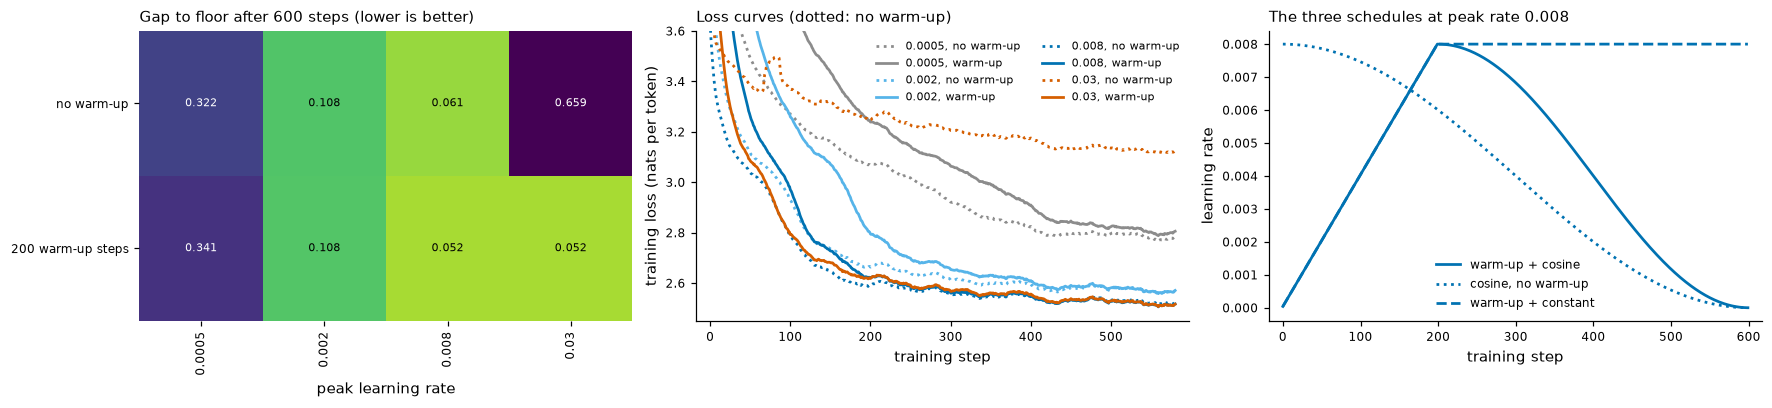

In [8]:
smooth = lambda v, k=20: np.convolve(v, np.ones(k) / k, mode="valid")
LR_COL = dict(zip(LRS, [viz.GREY, viz.SKY, viz.BLUE, viz.VERMILION]))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
viz.heat(axes[0], gap_grid.values, xlabels=[f"{lr:g}" for lr in LRS], ylabels=list(gap_grid.index), annotate=True, fmt="{:.3f}", cmap="viridis_r", vmin=0, vmax=0.4)
axes[0].set_xlabel("peak learning rate"); axes[0].set_title("Gap to floor after 600 steps (lower is better)")
for (lr, wu), r in grid.items():
    axes[1].plot(smooth(r["loss"]), color=LR_COL[lr], ls="-" if wu else ":", label=f"{lr:g}, {'warm-up' if wu else 'no warm-up'}")
axes[1].set_ylim(2.45, 3.6); axes[1].set_xlabel("training step"); axes[1].set_ylabel("training loss (nats per token)"); axes[1].set_title("Loss curves (dotted: no warm-up)")
axes[1].legend(fontsize=7, ncol=2)
for (lr, wu, r, lab, ls) in [(8e-3, 200, grid[(8e-3, 200)], "warm-up + cosine", "-"), (8e-3, 0, grid[(8e-3, 0)], "cosine, no warm-up", ":"), (8e-3, 200, constant, "warm-up + constant", "--")]:
    axes[2].plot(r["lr"], color=viz.BLUE, ls=ls, label=lab)
axes[2].set_xlabel("training step"); axes[2].set_ylabel("learning rate"); axes[2].set_title("The three schedules at peak rate 0.008"); axes[2].legend(fontsize=8)
plt.show()

### Try it: pick a learning rate and a warm-up

Static preview at the default settings {'peak_rate': 0.008, 'warm_up_steps': 200}. Run the notebook to get the controls.


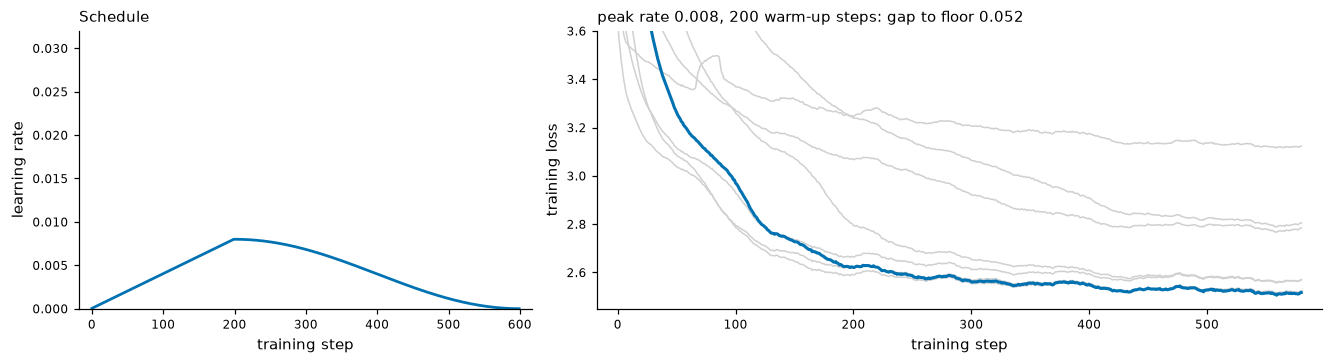

In [9]:
def recipe_explorer(peak_rate=0.008, warm_up_steps=200):
    r = grid[(peak_rate, warm_up_steps)]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw=dict(width_ratios=[1, 1.6]))
    axes[0].plot(r["lr"], color=viz.BLUE); axes[0].set_xlabel("training step"); axes[0].set_ylabel("learning rate"); axes[0].set_ylim(0, 0.032); axes[0].set_title("Schedule")
    for key, other in grid.items():
        axes[1].plot(smooth(other["loss"]), color="#D0D0D0", lw=1)
    axes[1].plot(smooth(r["loss"]), color=viz.BLUE, lw=2)
    axes[1].set_ylim(2.45, 3.6); axes[1].set_xlabel("training step"); axes[1].set_ylabel("training loss")
    axes[1].set_title(f"peak rate {peak_rate:g}, {warm_up_steps} warm-up steps: gap to floor {r['gap']:.3f}")
    plt.show()
viz.explore(recipe_explorer, peak_rate=[8e-3, 5e-4, 2e-3, 3e-2], warm_up_steps=[200, 0])

**Reading the result.**

* *Too small a rate just wastes the budget.* At 0.0005 the gap after 600 steps is 0.32 to 0.34, three times that of
  the next rate up.
* *The rate used in notebooks 01 to 04 was not the best one.* At 0.002 the gap is 0.108; at 0.008 it is 0.061
  without warm-up and 0.052 with it. We kept 0.002 throughout the series for comparability, and this is what it cost.
* *Warm-up widens the range of rates that work.* At 0.03 the run without warm-up fails: the loss stalls above 3.1 and
  the gap is 0.659. The same rate with 200 warm-up steps gives 0.052, as good as anything in the table. Warm-up did
  not improve the best result here; it made a four-times larger rate safe, which matters because nobody knows the
  best rate of a new model in advance.
* *Warm-up is not free at small rates.* At 0.0005 it makes things slightly worse (0.341 against 0.322), because
  those 200 steps are spent at even less than the small rate.
* *Decaying the rate helps.* At 0.008 with warm-up, cosine decay ends at 0.052 and a constant rate at 0.075. The
  small steps at the end let the model settle.

This is consistent with notebook 03, where a pre-norm model trained without warm-up at a rate of 0.005. Pre-norm
tolerates large early updates up to a point; warm-up moves that point further out.

## 5. Clipping and weight decay

**Gradient clipping** rescales any gradient whose length exceeds a threshold (notebook 02, section 2). It is in
every recipe as insurance against a single bad batch. The runs above recorded the gradient's length before clipping
at every step, so we can see how often the insurance paid out.

**Weight decay** shrinks every weight a little at each step, which discourages the model from fitting the training
set with large, fragile weights. There are two ways to do it, and with Adam they are not the same.

* **L2 penalty, the older way (Adam, [Kingma & Ba, 2014](https://arxiv.org/abs/1412.6980)).** Add $\lambda w$ to the gradient. Adam then divides the
  gradient, penalty included, by its running estimate of the gradient's size, so weights with large gradients are
  decayed less than weights with small ones.
* **Decoupled decay (AdamW, [Loshchilov & Hutter, 2017](https://arxiv.org/abs/1711.05101)).** Apply Adam to the loss alone, and separately multiply every
  weight by $(1 - \eta\lambda)$. Every weight is decayed at the same relative rate.

Weight decay matters when a model can memorise its training set, so we test it where that happens: 1,000 training
documents instead of 20,000. Each optimiser is run with several decay strengths.

train loss  test loss
optimiser         decay strength                       
AdamW (decoupled) 0.000                1.817      3.753
                  0.300                1.931      3.466
                  1.000                2.287      2.926
                  3.000                2.876      2.914
Adam + L2 penalty 0.003                2.555      2.682
                  0.010                2.875      2.906
                  0.030                3.242      3.274
                  0.100                3.537      3.532

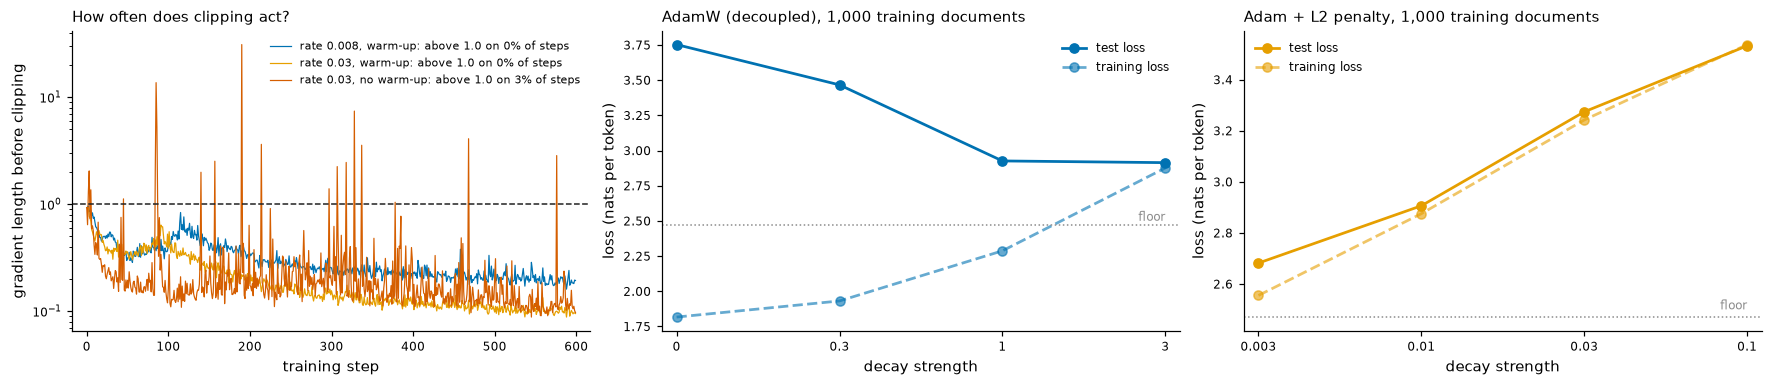

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for (lr, wu), col in [((8e-3, 200), viz.BLUE), ((3e-2, 200), viz.ORANGE), ((3e-2, 0), viz.VERMILION)]:
    g = np.array(grid[(lr, wu)]["grad_norm"])
    axes[0].plot(g, color=col, lw=0.8, label=f"rate {lr:g}, {'warm-up' if wu else 'no warm-up'}: above 1.0 on {np.mean(g > 1):.0%} of steps")
axes[0].axhline(1.0, color=viz.BLACK, ls="--", lw=1); axes[0].set_yscale("log"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("gradient length before clipping")
axes[0].set_title("How often does clipping act?"); axes[0].legend(fontsize=7)

small_set = train["tokens"][:1000]
def decay_run(optimizer, wd):
    set_seed(0); m = T.Transformer(**BASE)
    r = S.fit(m, small_set, steps=500, optimizer=optimizer, weight_decay=wd)
    return {"train loss": float(np.mean(r["loss"][-50:])), "test loss": W.evaluate_lm(m.logprobs)["loss"]}
decay = {("AdamW (decoupled)", wd): decay_run("adamw", wd) for wd in (0.0, 0.3, 1.0, 3.0)}
decay.update({("Adam + L2 penalty", wd): decay_run("adam", wd) for wd in (0.003, 0.01, 0.03, 0.1)})
decay = pd.DataFrame(decay).T; decay.index.names = ["optimiser", "decay strength"]
display(decay.round(3))
for ax, opt, col in [(axes[1], "AdamW (decoupled)", viz.BLUE), (axes[2], "Adam + L2 penalty", viz.ORANGE)]:
    d = decay.loc[opt]; x = range(len(d))
    ax.plot(x, d["test loss"], "o-", color=col, label="test loss"); ax.plot(x, d["train loss"], "o--", color=col, alpha=0.6, label="training loss")
    ax.axhline(W.floor(), color=viz.GREY, ls=":", lw=1); ax.text(len(d) - 1, W.floor() + 0.03, "floor", fontsize=8, color=viz.GREY, ha="right")
    ax.set_xticks(list(x)); ax.set_xticklabels([f"{v:g}" for v in d.index]); ax.set_xlabel("decay strength"); ax.set_ylabel("loss (nats per token)")
    ax.set_title(f"{opt}, 1,000 training documents"); ax.legend(fontsize=8)
plt.show()

**Reading the result.**

*Clipping.* In the two runs that trained well, the gradient never exceeded the threshold: clipping acted on 0% of
steps. In the run that failed (rate 0.03, no warm-up) it acted on 3% of steps, on spikes up to about 30 times the
threshold, and the run failed anyway. Clipping is insurance: it costs nothing when training is healthy and limits
the damage of a rare spike. It is not a substitute for a sensible rate.

*Weight decay.* With 1,000 documents and no decay the model memorises: training loss 1.82, test loss 3.75, against a
floor of 2.47. Both methods trade training loss for test loss as the strength grows.

* With **AdamW** the test loss falls from 3.75 to 3.47, 2.93 and 2.91. At a strength of 3 the training and test
  losses meet (2.88 and 2.91): nothing is memorised any more.
* With **Adam and an L2 penalty** the best strength tried, 0.003, gives 2.68, and stronger settings quickly do
  worse (2.91, 3.27, 3.53).

Two honest observations. First, the best test loss in this experiment came from the older method (2.68 against
2.91). We tried four strengths of each, and a finer search could change the ranking; this experiment does not show
that AdamW generalises better. Second, what clearly differs is what the number means. The useful strengths are
three orders of magnitude apart (0.003 against 1 to 3), and the L2 penalty is far more sensitive: tripling it from
its best value costs 0.22 nats, while tripling AdamW's from 1 to 3 changes the test loss by 0.01. Inside Adam, the
penalty is rescaled by the optimiser's own statistics, so its effect depends on the gradients; decoupled decay does
not. That predictability, and the fact that the decay strength no longer has to be retuned with the learning rate,
is the argument of [Loshchilov & Hutter, 2017](https://arxiv.org/abs/1711.05101) that this experiment supports.

## 6. Two architectural choices that belong to the recipe: context length and weight tying

**Context length.** A transformer is trained on windows of a fixed length. Longer windows cost more (attention grows
with the square of the length) and let the model learn longer dependencies. We train on windows of 16, 32 and 64
tokens cut from the same documents and test recall at distances up to 56 tokens. A model trained on 16-token windows
has never seen a binding more than about 13 tokens back.

**Weight tying** ([Press & Wolf, 2016](https://arxiv.org/abs/1608.05859)). The model has two tables with one row per token: the input embedding, which turns
a token into a vector, and the output layer, which scores each token against the final state. Tying uses one table
for both. In a real model with a vocabulary of 50,000 this saves tens of millions of parameters.

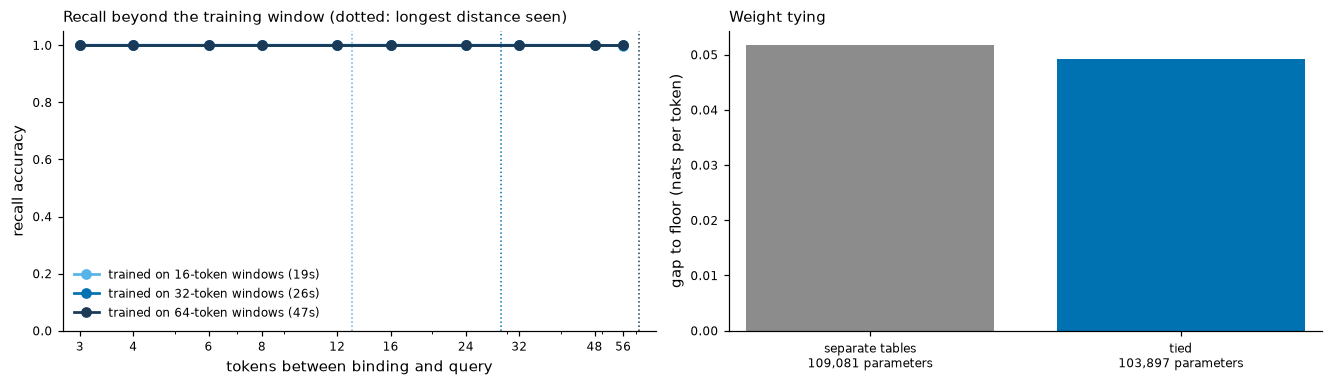

,gap to floor on full documents,recall at 8,recall at 16,recall at 32,recall at 56
16-token windows,0.248,1.0,1.0,1.0,0.998
32-token windows,0.161,1.0,1.0,1.0,1.000
64-token windows,0.052,1.0,1.0,1.0,1.000


,parameters,gap to floor
separate tables,109081.0,0.0517
tied,103897.0,0.0491


In [11]:
def windows(tokens, L, seed=0):
    starts = np.random.default_rng(seed).integers(0, tokens.shape[1] - L + 1, len(tokens))
    return np.stack([t[s:s + L] for t, s in zip(tokens, starts)])
ctx = {}
for L in (16, 32, 64):
    set_seed(0); m = T.Transformer(**BASE); t0 = time.time()
    S.fit(m, windows(train["tokens"], L), steps=1500)
    ctx[L] = dict(model=m, seconds=time.time() - t0, **W.evaluate_lm(m.logprobs))
set_seed(0); tied = T.Transformer(tie=True, **BASE); S.fit(tied, train["tokens"], steps=1500)
tied_res = W.evaluate_lm(tied.logprobs)
dists = list(W.RECALL_DISTANCES)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for L, col in zip((16, 32, 64), [viz.SKY, viz.BLUE, "#1B3A57"]):
    axes[0].plot(dists, [ctx[L]["recall"][d] for d in dists], "o-", color=col, label=f"trained on {L}-token windows ({ctx[L]['seconds']:.0f}s)")
    axes[0].axvline(L - 3, color=col, ls=":", lw=1)
axes[0].set_xscale("log"); axes[0].set_xticks(dists); axes[0].set_xticklabels(dists); axes[0].tick_params(axis="x", which="minor", labelbottom=False)
axes[0].set_ylim(0, 1.05); axes[0].set_xlabel("tokens between binding and query"); axes[0].set_ylabel("recall accuracy"); axes[0].legend(fontsize=8)
axes[0].set_title("Recall beyond the training window (dotted: longest distance seen)")
tie_table = pd.DataFrame({"separate tables": {"parameters": ctx[64]["model"].n_params(), "gap to floor": ctx[64]["gap"]},
                          "tied": {"parameters": tied.n_params(), "gap to floor": tied_res["gap"]}}).T
axes[1].bar([0, 1], tie_table["gap to floor"], color=[viz.GREY, viz.BLUE]); axes[1].set_xticks([0, 1])
axes[1].set_xticklabels([f"{n}\n{int(p):,} parameters" for n, p in zip(tie_table.index, tie_table["parameters"])]); axes[1].set_ylabel("gap to floor (nats per token)")
axes[1].set_title("Weight tying")
plt.show()
display(pd.DataFrame({f"{L}-token windows": {"gap to floor on full documents": ctx[L]["gap"], **{f"recall at {d}": ctx[L]["recall"][d] for d in (8, 16, 32, 56)}} for L in (16, 32, 64)}).T.round(3))
display(tie_table.round(4))

**Reading the result.**

* *Recall does not depend on the training window.* All three models recall perfectly at every distance, including
  the model trained on 16-token windows asked about a binding 56 tokens back (0.998). With a relative position
  scheme, a lookup learned at short range works at long range (notebook 03, section 4). The planned demonstration
  that a short context limits long-range recall did not happen, and we report that.
* *The short-window models are much worse language models of whole documents.* Their gap to the floor on full
  64-token documents is 0.248 and 0.161, against 0.052 for the model trained on full documents. Two things differ and
  this experiment does not separate them: the short-window models saw four and two times fewer tokens in the same
  number of steps, and they never practised accumulating evidence over more than 16 or 32 tokens, which is how the
  document's style and topic are inferred.
* *Shorter windows are cheaper*: about 20, 30 and 50 seconds for the same 1,500 steps.
* *Weight tying* gives a gap of 0.049 against 0.052 with 5% fewer parameters (103,897 against 109,081). The
  difference in quality is within what a second seed would change; the point is that nothing is lost. With our
  81-token vocabulary the saving is small. With a 50,000-piece vocabulary and a 1,000-dimensional model the shared
  table would have 50 million entries.

# Part C · Scale

## 7. Model size, data and compute

The central empirical fact of the last several years is that language models get predictably better as they get
bigger, **provided the data and the training time grow with them** ([Kaplan et al., 2020](https://arxiv.org/abs/2001.08361)). The second half of that sentence
is the part that is easy to forget, and [Hoffmann et al., 2022](https://arxiv.org/abs/2203.15556) showed that well-known models had been made too big for the
data they were trained on: for a fixed compute budget there is a best size, and it is smaller than people had assumed.

Three experiments, with the model's width as the size (16, 32, 64 or 128 dimensions; 9,000 to 415,000 parameters).

1. **Size, with all the data.** Each size is trained on the full 20,000 documents and measured every 250 steps.
2. **Size against data.** The three smaller sizes are trained on 500, 2,000 and 8,000 documents as well.
3. **Size against compute.** We charge each run a cost of *parameters x tokens processed* and ask which size is best
   at each budget. No extra training is needed: the curves from experiment 1 are read at equal cost.

In [12]:
def log_fn(model):
    ev = W.evaluate_lm(model.logprobs, distances=(8, 32)); b = W.recall_by_bindings(model.logprobs)
    return {"gap": ev["gap"], "recall, 1 binding": ev["recall_mean"], "recall, 2 bindings": b[2], "recall, 3 bindings": b[3]}
def size_run(d, n_docs=20000, steps=1000):
    set_seed(0); m = T.Transformer(d=d, **BASE); t0 = time.time()
    r = S.fit(m, train["tokens"][:n_docs], steps=steps, log_every=250, log_fn=log_fn)
    return dict(model=m, log=pd.DataFrame(r["log"]).set_index("step"), params=m.n_params(), seconds=time.time() - t0)
SIZES = [16, 32, 64, 128]
full = {16: size_run(16, steps=2000), 32: size_run(32, steps=2000), 64: size_run(64, steps=3000), 128: size_run(128, steps=1500)}
for d in SIZES:
    print(f"width {d:3d}: {full[d]['params']:7,} parameters, {len(full[d]['log']) * 250:5,} steps in {full[d]['seconds']:4.0f}s, final gap {full[d]['log']['gap'].iloc[-1]:.3f}")
DATA = [500, 2000, 8000]
small = {(d, n): size_run(d, n) for d in (16, 32, 64) for n in DATA}

width  16:   9,097 parameters, 2,000 steps in   41s, final gap 0.095
width  32:  30,201 parameters, 2,000 steps in   47s, final gap 0.061
width  64: 109,081 parameters, 3,000 steps in  103s, final gap 0.039
width 128: 414,681 parameters, 1,500 steps in  105s, final gap 0.057


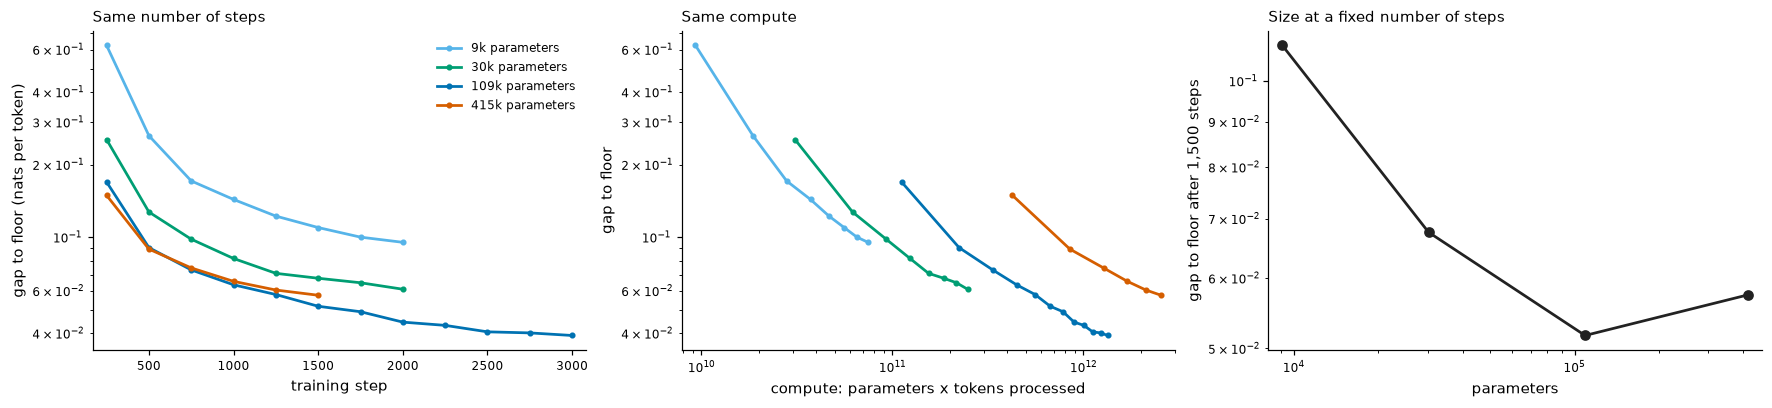

gap after step,250,500,750,1000,1250,1500,1750,2000,2250,2500,2750,3000
9k parameters,0.624,0.263,0.171,0.143,0.122,0.110,0.100,0.095,NaN,NaN,NaN,NaN
30k parameters,0.254,0.127,0.098,0.082,0.071,0.068,0.065,0.061,NaN,NaN,NaN,NaN
109k parameters,0.169,0.091,0.073,0.063,0.058,0.052,0.049,0.044,0.043,0.041,0.04,0.039
415k parameters,0.149,0.089,0.075,0.066,0.060,0.057,NaN,NaN,NaN,NaN,NaN,NaN


compute budget,4.0e+10,7.0e+10,1.2e+11,2.4e+11,5.0e+11,1.2e+12
9k parameters,0.137,0.097,NaN,NaN,NaN,NaN
30k parameters,0.207,0.118,0.083,0.062,NaN,NaN
109k parameters,NaN,NaN,0.161,0.087,0.061,0.040
415k parameters,NaN,NaN,NaN,NaN,0.135,0.077


best size at each budget: {'4.0e+10': '9k parameters', '7.0e+10': '9k parameters', '1.2e+11': '30k parameters', '2.4e+11': '30k parameters', '5.0e+11': '109k parameters', '1.2e+12': '109k parameters'}


In [13]:
SIZE_COL = dict(zip(SIZES, [viz.SKY, viz.GREEN, viz.BLUE, viz.VERMILION]))
label = lambda d: f"{full[d]['params'] / 1000:.0f}k parameters"
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for d in SIZES:
    lg = full[d]["log"]
    axes[0].plot(lg.index, lg["gap"], "o-", ms=3, color=SIZE_COL[d], label=label(d))
    axes[1].plot(full[d]["params"] * lg.index * 64 * 64, lg["gap"], "o-", ms=3, color=SIZE_COL[d], label=label(d))
axes[0].set_yscale("log"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("gap to floor (nats per token)"); axes[0].set_title("Same number of steps"); axes[0].legend(fontsize=8)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("compute: parameters x tokens processed"); axes[1].set_ylabel("gap to floor"); axes[1].set_title("Same compute")
at1500 = pd.Series({full[d]["params"]: full[d]["log"].loc[1500, "gap"] for d in SIZES})
axes[2].plot(at1500.index, at1500.values, "o-", color=viz.BLACK)
axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_xlabel("parameters"); axes[2].set_ylabel("gap to floor after 1,500 steps"); axes[2].set_title("Size at a fixed number of steps")
plt.show()
steps_table = pd.DataFrame({label(d): full[d]["log"]["gap"] for d in SIZES}).T; steps_table.columns.name = "gap after step"
display(steps_table.round(3))

# which size is best at each compute budget? read every curve at the same cost (linear interpolation between measurements)
budgets = np.array([4e10, 7e10, 1.2e11, 2.4e11, 5e11, 1.2e12])          # chosen so that at least two sizes have been trained to each budget
def gap_at(d, budget):
    lg = full[d]["log"]; cost = full[d]["params"] * lg.index.values * 64 * 64
    return np.nan if budget < cost[0] or budget > cost[-1] else float(np.interp(np.log(budget), np.log(cost), lg["gap"].values))
frontier = pd.DataFrame({label(d): [gap_at(d, b) for b in budgets] for d in SIZES}, index=[f"{b:.1e}" for b in budgets]).T; frontier.columns.name = "compute budget"
display(frontier.round(3))
print("best size at each budget:", {c: frontier[c].idxmin() for c in frontier.columns if frontier[c].notna().any()})

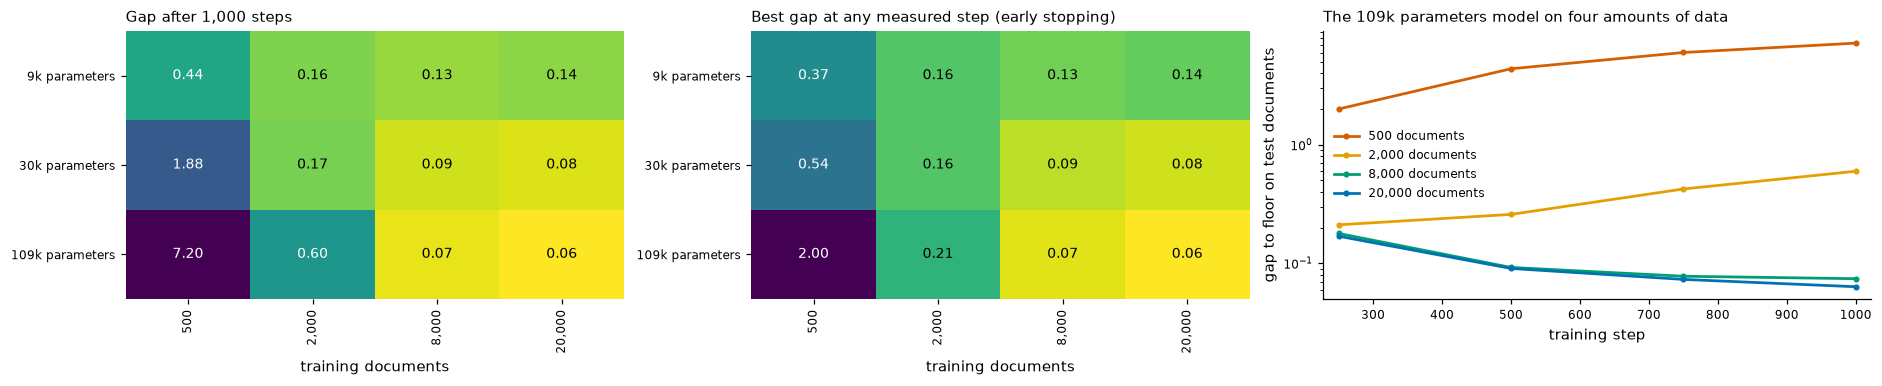

,500 documents,"2,000 documents","8,000 documents","20,000 documents"
9k parameters,0.436,0.159,0.132,0.143
30k parameters,1.877,0.168,0.089,0.082
109k parameters,7.204,0.598,0.074,0.063


,500 documents,"2,000 documents","8,000 documents","20,000 documents"
9k parameters,0.373,0.159,0.132,0.143
30k parameters,0.539,0.159,0.089,0.082
109k parameters,2.003,0.211,0.074,0.063


In [14]:
rows3 = [16, 32, 64]
final = pd.DataFrame([[small[(d, n)]["log"]["gap"].iloc[-1] for n in DATA] + [full[d]["log"].loc[1000, "gap"]] for d in rows3],
                     index=[label(d) for d in rows3], columns=[f"{n:,} documents" for n in DATA + [20000]])
best = pd.DataFrame([[small[(d, n)]["log"]["gap"].min() for n in DATA] + [full[d]["log"].loc[:1000, "gap"].min()] for d in rows3], index=final.index, columns=final.columns)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1.1]))
viz.heat(axes[0], np.log10(final.values), xlabels=[f"{n:,}" for n in DATA + [20000]], ylabels=list(final.index), cmap="viridis_r")
viz.heat(axes[1], np.log10(best.values), xlabels=[f"{n:,}" for n in DATA + [20000]], ylabels=list(final.index), cmap="viridis_r")
for ax, tab, title in [(axes[0], final, "Gap after 1,000 steps"), (axes[1], best, "Best gap at any measured step (early stopping)")]:
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if tab.values[i, j] > 0.3 else "black")
    ax.set_xlabel("training documents"); ax.set_title(title)
for n, col in zip(DATA, [viz.VERMILION, viz.ORANGE, viz.GREEN]):
    lg = small[(64, n)]["log"]; axes[2].plot(lg.index, lg["gap"], "o-", ms=3, color=col, label=f"{n:,} documents")
axes[2].plot(full[64]["log"].loc[:1000].index, full[64]["log"].loc[:1000, "gap"], "o-", ms=3, color=viz.BLUE, label="20,000 documents")
axes[2].set_yscale("log"); axes[2].set_xlabel("training step"); axes[2].set_ylabel("gap to floor on test documents"); axes[2].set_title(f"The {label(64)} model on four amounts of data"); axes[2].legend(fontsize=8)
plt.show()
display(final.round(3)); display(best.round(3))

**Reading the result.**

*Size at the same number of steps.* After 1,500 steps the gap is 0.110, 0.068, 0.052 and 0.057 for 9k, 30k, 109k and
415k parameters. Bigger is better up to 109k. The 415k model is slightly *worse* than the 109k model at the same
step, and each of its steps costs about twice as much time: its 1,500 steps took as long as the 109k model's 3,000.

*Size at the same compute.* Charge each run *parameters x tokens processed* and read the curves at equal cost (the second
table above). At every budget where two sizes were trained, the smaller one is ahead. The 9k model beats the 30k
model at budgets of 4.0e10 and 7.0e10 (0.137 against 0.207, and 0.097 against 0.118). The 30k model beats the 109k
model at 1.2e11 and 2.4e11 (0.083 against 0.161, and 0.062 against 0.087). The 109k model beats the 415k model at
5.0e11 and 1.2e12 (0.061 against 0.135, and 0.040 against 0.077). The best size does grow with the budget, from 9k
to 30k to 109k, but with a fixed amount of compute a smaller model trained for longer was better than a larger one
trained briefly. This is the finding of [Hoffmann et al., 2022](https://arxiv.org/abs/2203.15556) in miniature. The comparison has a limit: at each budget we have
only two sizes, the smaller one near the end of its run and the larger one near the start of its own.

*Size against data.* The table after 1,000 steps reads differently along its rows and its columns.

* With 20,000 documents, bigger is better: 0.143, 0.082, 0.063.
* With 500 documents, bigger is catastrophically worse: 0.44, 1.88, 7.20. The 109k model has memorised its 500
  documents and assigns almost no probability to anything else.
* The smallest model stops benefiting from data early (0.16 with 2,000 documents, 0.13 with 8,000, 0.14 with
  20,000). The largest keeps benefiting (0.60, 0.07, 0.06).
* Stopping at the best measured step repairs part of the damage (right-hand table: 2.00 and 0.21 for the 109k model
  on 500 and 2,000 documents) and does not close the gap to the small model (0.37 and 0.16).

A larger model is a bet that the data and the compute to train it are available. When they are, it wins. When they
are not, a smaller model is the better model, and that is the practical content of the scaling-law papers.

### When does the model start to use its context?

The same runs recorded recall. Recall with **one** binding is the ability to look something up at all. Recall with
**two** bindings is the ability to look up the *right* thing, which notebook 03 found to appear late and suddenly.

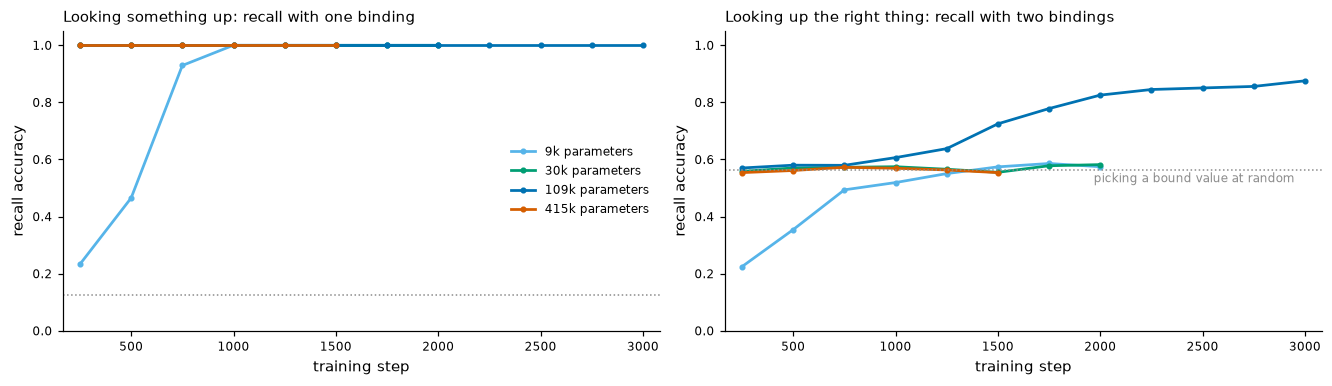

step,250,500,750,1000,1250,1500,1750,2000,2250,2500,2750,3000
9k parameters,0.23,0.46,0.93,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
30k parameters,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
109k parameters,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
415k parameters,1.00,1.00,1.00,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN


step,250,500,750,1000,1250,1500,1750,2000,2250,2500,2750,3000
9k parameters,0.22,0.35,0.49,0.52,0.55,0.57,0.59,0.57,NaN,NaN,NaN,NaN
30k parameters,0.56,0.57,0.57,0.57,0.57,0.55,0.58,0.58,NaN,NaN,NaN,NaN
109k parameters,0.57,0.58,0.58,0.61,0.64,0.72,0.78,0.83,0.84,0.85,0.86,0.88
415k parameters,0.55,0.56,0.57,0.57,0.56,0.55,NaN,NaN,NaN,NaN,NaN,NaN


saved the 3,000-step, width-64 model to checkpoints/base_lm.pt (a local file, not part of the repository)


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for d in SIZES:
    lg = full[d]["log"]
    axes[0].plot(lg.index, lg["recall, 1 binding"], "o-", ms=3, color=SIZE_COL[d], label=label(d))
    axes[1].plot(lg.index, lg["recall, 2 bindings"], "o-", ms=3, color=SIZE_COL[d], label=label(d))
axes[0].axhline(1 / 8, color=viz.GREY, ls=":", lw=1); axes[1].axhline(0.5625, color=viz.GREY, ls=":", lw=1); axes[1].text(2950, 0.52, "picking a bound value at random", fontsize=8, color=viz.GREY, ha="right")
for ax, t in zip(axes, ["Looking something up: recall with one binding", "Looking up the right thing: recall with two bindings"]):
    ax.set_ylim(0, 1.05); ax.set_xlabel("training step"); ax.set_ylabel("recall accuracy"); ax.set_title(t)
axes[0].legend(fontsize=8)
plt.show()
display(pd.DataFrame({label(d): full[d]["log"]["recall, 1 binding"] for d in SIZES}).T.round(2))
display(pd.DataFrame({label(d): full[d]["log"]["recall, 2 bindings"] for d in SIZES}).T.round(2))
os.makedirs(CKPT_DIR, exist_ok=True)
torch.save({"config": full[64]["model"].cfg, "state": full[64]["model"].state_dict()}, os.path.join(CKPT_DIR, "base_lm.pt"))
print("saved the 3,000-step, width-64 model to checkpoints/base_lm.pt (a local file, not part of the repository)")

**Reading the result.**

* *Looking something up.* The three larger models recall a single binding perfectly at the first measurement, step
  250. The 9k model is at 0.23 at step 250, 0.46 at step 500, 0.93 at step 750 and reaches 1.00 at step 1,000. A
  smaller model acquires the same ability later.
* *Looking up the right thing.* Only the 109k model gets beyond the level of picking a bound value at random
  (0.56): it is at 0.58 at step 750, 0.72 at step 1,500 and 0.88 at step 3,000. The 9k model climbs from 0.22 to
  between 0.55 and 0.59 as it learns to look anything up at all, and stops there; the 30k model is at 0.55 to 0.58
  throughout. The 415k model
  is at 0.55 at step 1,500, when the 109k model was already at 0.72: here, more parameters did not bring the ability
  sooner. These are single runs, and we did not train the 415k model long enough to see whether it follows later.
* The rise is gradual here. In notebook 03, with a different position scheme, the same ability appeared abruptly
  after about 11,000 steps. When and how an ability appears depends on the architecture as well as on size and
  training time, and one run cannot tell what is typical.

The 109k model after 3,000 steps is saved as `checkpoints/base_lm.pt`.

## 8. Design choices: what changed, and the recipe in three well-known models

| Choice | Earlier | What the field moved to | Why | Measured here |
|---|---|---|---|---|
| Vocabulary | whole words with an "unknown" token | sub-words: BPE ([Sennrich et al., 2015](https://arxiv.org/abs/1508.07909)), WordPiece, unigram models ([Kudo & Richardson, 2018](https://arxiv.org/abs/1808.06226)) | No word is ever out of vocabulary | Whole words are the most efficient on seen text; one unseen word costs them 1.83 nats on the next word, against 0.05 to 0.21 for sub-words (sections 2 and 3) |
| Learning-rate schedule | constant, or warm-up then inverse square root (2017) | linear warm-up, then cosine decay ([Loshchilov & Hutter, 2016](https://arxiv.org/abs/1608.03983)) | Warm-up allows a much larger peak rate; decay settles the model at the end | Warm-up makes a peak rate of 0.03 usable (gap 0.052, against 0.659 without); cosine decay beats a constant rate (0.052 against 0.075) (section 4) |
| Gradient clipping | none | clip the gradient norm, usually at 1.0 | Insurance against rare large gradients | Never active in the runs that trained well; active on 3% of steps in the run that failed (section 5) |
| Weight decay | L2 penalty inside Adam ([Kingma & Ba, 2014](https://arxiv.org/abs/1412.6980)) | decoupled decay, AdamW ([Loshchilov & Hutter, 2017](https://arxiv.org/abs/1711.05101)) | The same relative decay for every weight; decay strength no longer entangled with gradient scale | Both reduce overfitting on 1,000 documents; best test loss 2.68 (L2) and 2.91 (AdamW) among the strengths tried; L2 far more sensitive to its strength (section 5) |
| Output layer | separate from the input embedding | tied to it ([Press & Wolf, 2016](https://arxiv.org/abs/1608.05859)) | Fewer parameters at the same quality | Gap 0.049 tied against 0.052 untied, with 5% fewer parameters (section 6) |
| Context length | 512 tokens (2018) | thousands to hundreds of thousands | Longer documents and prompts; cost grows with the square of the length | Recall works beyond the training window; the gap on full documents is far worse for short windows: 0.25, 0.16, 0.05 (section 6) |
| Choosing the size | as large as fits | sized to the data and compute available ([Kaplan et al., 2020](https://arxiv.org/abs/2001.08361), [Hoffmann et al., 2022](https://arxiv.org/abs/2203.15556)) | For a fixed budget there is a best size | At equal steps the 415k model is no better than the 109k model; at equal compute the smaller of any two sizes we could compare was ahead (section 7) |

**The recipe in three well-known models** (from the cited papers):

| Model | Tokeniser | Optimiser | Schedule | Weight decay | Clipping |
|---|---|---|---|---|---|
| BERT ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)) | WordPiece, 30,000 pieces | Adam with L2 penalty | 10,000 warm-up steps, then linear decay | 0.01 | not stated |
| GPT-3 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)) | BPE, about 50,000 pieces | Adam | warm-up, then cosine decay to 10% | 0.1 | 1.0 |
| LLaMA ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)) | BPE, 32,000 pieces | AdamW | 2,000 warm-up steps, then cosine decay | 0.1 | 1.0 |

One more observation about large models, which this notebook does not reproduce: as models grow past the point where
they can memorise the training set, test error can fall, rise and then fall again ([Nakkiran et al., 2019](https://arxiv.org/abs/1912.02292)). And what a
transformer can learn to do *from its context alone* has become a research subject of its own ([Garg et al., 2022](https://arxiv.org/abs/2208.01066)).

## 9. Scorecard

In [16]:
rows = []
for d in SIZES:
    m = full[d]["model"]; ev = W.evaluate_lm(m.logprobs)
    rows.append(W.scorecard_row(f"causal transformer, {full[d]['params'] / 1000:.0f}k parameters, {len(full[d]['log']) * 250:,} steps", ev,
                                recall_natural=W.natural_recall(m.logprobs).correct.mean(), probe_style=W.probe(m.features, 100, "style"),
                                params=full[d]["params"], train_seconds=full[d]["seconds"]))
metrics.append_rows(rows, "05_scaling")
card = metrics.load_scorecard()
show = [c for c in ["notebook", "model", "gap", "recall_d8", "recall_d32", "recall_natural", "probe_style", "params", "train_seconds"] if c in card.columns]
display(card[card.notebook.isin(["03_transformer", "05_scaling"])][show].round(3))

,notebook,model,gap,recall_d8,recall_d32,recall_natural,probe_style,params,train_seconds
12,03_transformer,"transformer, 2017 block",0.159,0.154,0.122,0.137,0.992,109905.0,40.227
13,03_transformer,"transformer, pre-norm + RMSNorm",0.085,1.000,1.000,0.633,0.928,109713.0,44.623
14,03_transformer,"transformer, + RoPE",0.058,1.000,1.000,0.639,0.749,109713.0,47.953
15,03_transformer,"transformer, modern block (RoPE, RMSNorm, SwiGLU)",0.059,1.000,1.000,0.642,0.991,108817.0,49.842
16,03_transformer,"transformer, modern + 1 key/value head",0.062,1.000,1.000,0.636,0.997,96529.0,47.895
17,03_transformer,"transformer, modern + MoE (4 experts, top-1)",0.065,1.000,1.000,0.635,0.982,305169.0,99.390
18,03_transformer,"transformer, modern block, 13,500 steps",0.046,1.000,1.000,0.975,0.971,108817.0,476.455
22,05_scaling,"causal transformer, 9k parameters, 2,000 steps",0.095,1.000,1.000,0.633,0.437,9097.0,40.723
23,05_scaling,"causal transformer, 30k parameters, 2,000 steps",0.061,1.000,1.000,0.643,0.860,30201.0,46.648
24,05_scaling,"causal transformer, 109k parameters, 3,000 steps",0.039,1.000,1.000,0.833,0.744,109081.0,102.980


## Challenge Problem 1: The schedule of 2017

The original transformer used a different schedule: the learning rate rises linearly for `w` warm-up steps and then falls in proportion to the inverse
square root of the step number, $\eta_t \propto \min(t^{-1/2},\; t\,w^{-3/2})$. `S.fit` accepts a function as its `schedule` (step number to a multiplier
of the peak rate). Implement this schedule with `w = 200`, scaled so that its maximum is 1, and compare it with warm-up plus cosine decay at peak rates
0.008 and 0.03 for 600 steps. Plot both schedules. Which ends with the lower gap, and what is the learning rate of each at the last step?

In [17]:
# Start your code here

### Challenge Problem 1 Solution

,inverse square root: gap,cosine: gap,inverse square root: final rate,cosine: final rate
peak rate 0.008,0.0712,0.0525,0.0046,0.0
peak rate 0.03,0.0722,0.0518,0.0173,0.0


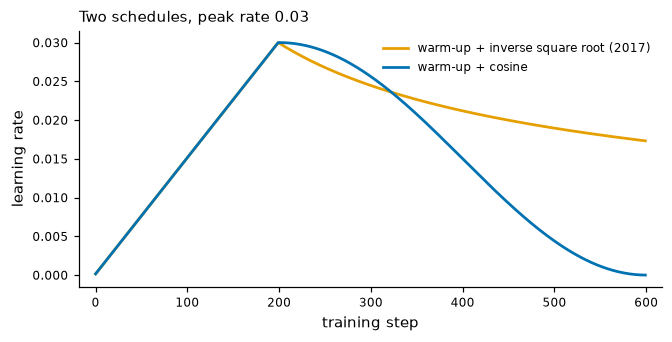

In [18]:
w = 200
inv_sqrt = lambda s: min((s + 1) ** -0.5, (s + 1) * w ** -1.5) / w ** -0.5          # equals 1 at step w
out = {}
for lr in (8e-3, 3e-2):
    r = recipe_run(lr, schedule=inv_sqrt)
    out[f"peak rate {lr:g}"] = {"inverse square root: gap": r["gap"], "cosine: gap": grid[(lr, 200)]["gap"],
                                 "inverse square root: final rate": r["lr"][-1], "cosine: final rate": grid[(lr, 200)]["lr"][-1]}
    last = r
display(pd.DataFrame(out).T.round(4))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(last["lr"], color=viz.ORANGE, label="warm-up + inverse square root (2017)"); ax.plot(grid[(3e-2, 200)]["lr"], color=viz.BLUE, label="warm-up + cosine")
ax.set_xlabel("training step"); ax.set_ylabel("learning rate"); ax.legend(fontsize=8); ax.set_title("Two schedules, peak rate 0.03"); plt.show()
# Read the table. Cosine decay ends with the lower gap at both peak rates: 0.053 and 0.052, against 0.071 and 0.072
# for the inverse-square-root schedule. The difference is where each schedule finishes. Cosine reaches a rate of zero
# at the last step. The 2017 schedule falls slowly: at step 600 it is still at 0.0046 and 0.0173, more than half of
# its peak, so the model never gets the small final steps that let it settle.
# The 2017 schedule has one advantage that a 600-step run does not show: it does not need to know when training will
# end. Cosine decay does.

## Challenge Problem 2: Early stopping against a smaller model

With 2,000 training documents the largest of the three grid models overfits: its test gap is lowest early and rises afterwards. Using the logs in
`small` (no new training), compare three ways of spending that small dataset: the 109k-parameter model at the end of training, the same model at its
best measured step, and the 9k-parameter model at the end of training. Which is best? What does the answer say about fixing overfitting by making the
model smaller?

In [19]:
# Start your code here

### Challenge Problem 2 Solution

In [20]:
n = 2000
big, little, mid = small[(64, n)]["log"]["gap"], small[(16, n)]["log"]["gap"], small[(32, n)]["log"]["gap"]
display(pd.DataFrame({"gap to floor": {f"{label(64)}, end of training (step {big.index[-1]})": big.iloc[-1],
                                       f"{label(64)}, best measured step (step {big.idxmin()})": big.min(),
                                       f"{label(32)}, end of training": mid.iloc[-1], f"{label(32)}, best measured step (step {mid.idxmin()})": mid.min(),
                                       f"{label(16)}, end of training": little.iloc[-1], f"{label(16)}, best measured step (step {little.idxmin()})": little.min()}}).round(3))
# Read the table. With 2,000 documents the 9k model at the end of training (0.159) is better than the 109k model at
# the end of training (0.598) and better than the 109k model stopped at its best measured step (0.211). Early stopping
# removes most of the damage of overfitting and still leaves the large model behind the small one. (We measured only
# every 250 steps, so the large model's true best may be a little earlier and a little better than 0.211.)
# With little data, choosing a smaller model was the better remedy here. The table in section 7 shows the order
# reversing by 8,000 documents (0.132 for the 9k model, 0.074 for the 109k model): the right size depends on the data.

,gap to floor
"109k parameters, end of training (step 1000)",0.598
"109k parameters, best measured step (step 250)",0.211
"30k parameters, end of training",0.168
"30k parameters, best measured step (step 750)",0.159
"9k parameters, end of training",0.159
"9k parameters, best measured step (step 1000)",0.159


## Final summary

* **Tokenisers.** Byte-pair encoding builds a vocabulary by repeatedly merging the most frequent pair of symbols. On
  our corpus it found the word endings first. Larger pieces train faster and better on text made of known words;
  smaller pieces survive words never seen. A whole-word model lost 1.83 nats on the word after one unknown word.
* **Learning rate.** The rate used throughout this series was four times too small. Warm-up made a rate of 0.03
  usable where it otherwise failed, and cosine decay beat a constant rate.
* **Clipping and weight decay.** Clipping never acted in healthy runs. Weight decay reduced memorisation with both
  Adam and AdamW; AdamW was not better here, but its strength was far less delicate to set.
* **Context length and tying.** Recall extended beyond the training window, which we did not expect; short windows
  still gave much worse models of full documents. Tying the output layer to the embedding lost nothing.
* **Scale.** With enough data a bigger model is better. With too little it is far worse, and at a fixed compute
  budget a smaller model trained for longer can win. Size has to be chosen together with data and compute.
* **Abilities appear on their own schedule.** A smaller model learned to look things up later than larger ones, and
  only one of four sizes began to look up the right thing in the time we gave it.
* This closes the language half of the series. Notebook 06 starts again with images: how models generated pictures
  before diffusion, and what went wrong with each approach.

## References

* Rico Sennrich, Barry Haddow, Alexandra Birch (2015). **Neural Machine Translation of Rare Words with Subword Units**. arXiv:1508.07909. [arxiv.org/abs/1508.07909](https://arxiv.org/abs/1508.07909)
* Taku Kudo, John Richardson (2018). **SentencePiece: A simple and language independent subword tokenizer and detokenizer for Neural Text Processing**. arXiv:1808.06226. [arxiv.org/abs/1808.06226](https://arxiv.org/abs/1808.06226)
* Diederik P. Kingma, Jimmy Ba (2014). **Adam: A Method for Stochastic Optimization**. arXiv:1412.6980. [arxiv.org/abs/1412.6980](https://arxiv.org/abs/1412.6980)
* Ilya Loshchilov, Frank Hutter (2016). **SGDR: Stochastic Gradient Descent with Warm Restarts**. arXiv:1608.03983. [arxiv.org/abs/1608.03983](https://arxiv.org/abs/1608.03983)
* Ilya Loshchilov, Frank Hutter (2017). **Decoupled Weight Decay Regularization**. arXiv:1711.05101. [arxiv.org/abs/1711.05101](https://arxiv.org/abs/1711.05101)
* Ofir Press, Lior Wolf (2016). **Using the Output Embedding to Improve Language Models**. arXiv:1608.05859. [arxiv.org/abs/1608.05859](https://arxiv.org/abs/1608.05859)
* Jared Kaplan, Sam McCandlish, Tom Henighan et al. (2020). **Scaling Laws for Neural Language Models**. arXiv:2001.08361. [arxiv.org/abs/2001.08361](https://arxiv.org/abs/2001.08361)
* Jordan Hoffmann, Sebastian Borgeaud, Arthur Mensch et al. (2022). **Training Compute-Optimal Large Language Models**. arXiv:2203.15556. [arxiv.org/abs/2203.15556](https://arxiv.org/abs/2203.15556)
* Preetum Nakkiran, Gal Kaplun, Yamini Bansal et al. (2019). **Deep Double Descent: Where Bigger Models and More Data Hurt**. arXiv:1912.02292. [arxiv.org/abs/1912.02292](https://arxiv.org/abs/1912.02292)
* Shivam Garg, Dimitris Tsipras, Percy Liang et al. (2022). **What Can Transformers Learn In-Context? A Case Study of Simple Function Classes**. arXiv:2208.01066. [arxiv.org/abs/2208.01066](https://arxiv.org/abs/2208.01066)
* Jacob Devlin, Ming-Wei Chang, Kenton Lee et al. (2018). **BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding**. arXiv:1810.04805. [arxiv.org/abs/1810.04805](https://arxiv.org/abs/1810.04805)
* Tom B. Brown, Benjamin Mann, Nick Ryder et al. (2020). **Language Models are Few-Shot Learners**. arXiv:2005.14165. [arxiv.org/abs/2005.14165](https://arxiv.org/abs/2005.14165)
* Hugo Touvron, Thibaut Lavril, Gautier Izacard et al. (2023). **LLaMA: Open and Efficient Foundation Language Models**. arXiv:2302.13971. [arxiv.org/abs/2302.13971](https://arxiv.org/abs/2302.13971)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).